# 🐍 Python Foundations for AI
## Class 7 — Databases & Data Pipelines

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
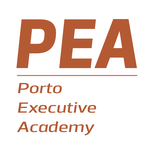
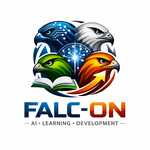
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | Why a database, and not a CSV? |
| 2 | A row is a tuple |
| 3 | Connecting, and creating a table |
| 4 | Adding rows — `INSERT` |
| 5 | Reading rows — `SELECT` |
| 6 | Changing and deleting rows — `UPDATE`, `DELETE` |
| 7 | pandas and SQL together |
| 8 | 🔗 Capstone — FALC-ON AI gets a long-term memory |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Say when a database is the right answer, and when a file will do
- Create a table, put rows in it, get them back, change and delete them
- Ask a database a question in SQL, and move data between pandas and SQL
- Store an AI assistant's conversations and feedback, and reload them later

### 🤖 Why AI needs a database

An AI model is **forgetful**: it answers, and remembers nothing. Our variables are no better — when the notebook stops, they are gone.

To give an assistant a real memory — the questions, its answers, and whether users liked them — the data must be **stored somewhere that lasts**. That somewhere is a **database**. Today you build FALC-ON AI's long-term memory.

---
## 1. Why a Database, and Not a CSV?

| | A CSV file | A database |
|---|-----------|-----------|
| Reading part of it | Load all of it, then filter | Ask for **only** the rows you want |
| Changing one row | Rewrite the whole file | Change that one row |
| Rules about the data | None — anything in any column | Each column has a type |
| Size | Fine up to a few hundred thousand rows | Millions |

> 💡 **A CSV is a document; a database is a system.** Data that is read once can live in a file. Data that is added to, corrected and questioned over time — like every conversation with an assistant — belongs in a database.

### The words

| Word | Means | You already know it as |
|------|-------|------------------------|
| **Table** | a grid of data with named columns | a DataFrame |
| **Row** | one record | one conversation turn |
| **Column** | one field, with a type | `question`, `answer`, `rating` |
| **SQL** | the language you ask a database in | — a new language, sent from Python as text |

We use **SQLite**: a whole database in a single file, built into Python, nothing to install.

---
## 2. A Row Is a Tuple

Databases hand rows back as **tuples**. A **tuple** is a list that **cannot be changed**, written with round brackets. You read it exactly like a list.

In [ ]:
row = ("ana", "how many classes?", "The course has 10 classes.", 5)

print(row)
print(row[1])                    # how many classes? - read it like a list
print(len(row))                  # 4

### Unpacking a tuple

You can take a tuple apart into separate variables in one line — one variable per value, in order.

In [ ]:
user, question, answer, rating = row

print(f"{user} asked '{question}' and rated the answer {rating}")

### A tuple with one value needs a comma

`("ana",)` is a tuple with one value. Without the comma, `("ana")` is just the text `"ana"` in brackets. You will need this form in a moment.

In [ ]:
print(type(("ana",)))            # type: tuple
print(type(("ana")))             # type: str - no comma, no tuple

---
## 3. Connecting, and Creating a Table

Every database program follows the same rhythm:

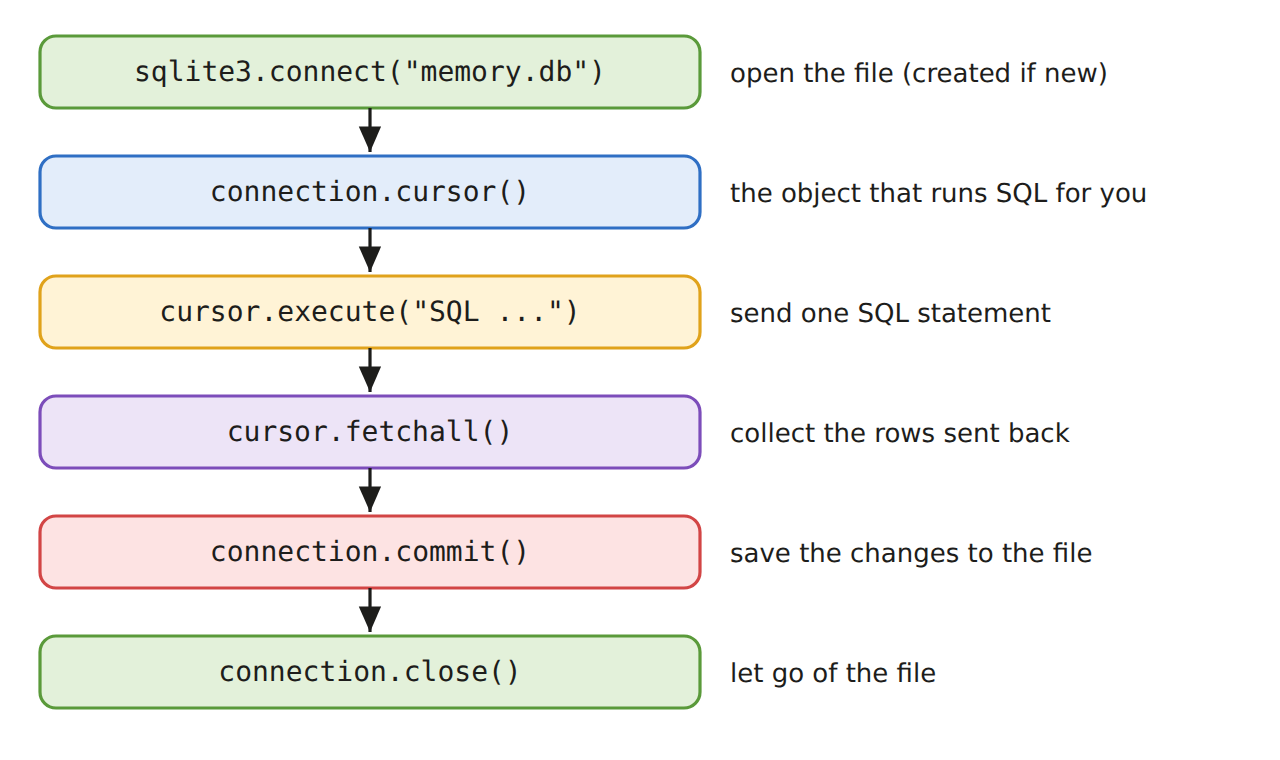

### Creating a table

`CREATE TABLE` names the table and lists its columns, each with a **type**:

| SQL type | Holds | In Python |
|----------|-------|-----------|
| `TEXT` | words | `str` |
| `INTEGER` | whole numbers | `int` |
| `REAL` | decimals | `float` |

`id INTEGER PRIMARY KEY` gives every row a number, filled in automatically.

> ⚠️ **A notebook gets re-run.** `CREATE TABLE IF NOT EXISTS` does nothing if the table is already there, and `DELETE FROM` empties it so every run starts clean. Without these two, re-running would crash, or double your rows.

> ⚠️ **Where the file lives:** `memory.db` is created in your Colab files space. It lasts until your Colab session ends. To keep it, download it from the files panel (📁 in the left sidebar).

In [ ]:
import sqlite3

connection = sqlite3.connect("memory.db")        # open the file, or create it
cursor = connection.cursor()                     # the object that runs SQL

cursor.execute("""
    CREATE TABLE IF NOT EXISTS memory (
        id       INTEGER PRIMARY KEY,
        user     TEXT,
        question TEXT,
        answer   TEXT,
        rating   INTEGER
    )
""")
cursor.execute("DELETE FROM memory")             # start clean, so re-running is safe
connection.commit()                              # nothing is saved until you commit

print("Table ready")

---
## 4. Adding Rows — `INSERT`

`INSERT INTO` adds a row. The values **never** go straight into the SQL text: you write a `?` for each one, and pass the values separately, as a **tuple**.

> ⚠️ Always use `?`. Gluing values into the SQL text breaks as soon as a value contains an apostrophe — like *"I don't know"* — and is the classic way databases get attacked.

> ⚠️ **Nothing is saved until `connection.commit()`.** Your code runs without error, but without the commit the file is unchanged.

In [ ]:
cursor.execute(
    "INSERT INTO memory (user, question, answer, rating) VALUES (?, ?, ?, ?)",
    ("ana", "how many classes?", "The course has 10 classes.", 5),
)
connection.commit()
print("1 row added")

### Many rows at once — `.executemany()`

It runs the same statement once for every tuple in a list.

In [ ]:
UNKNOWN = "Sorry, I don't know that yet."

turns = [
    ("ana",   "what is colab?",            "We write our code in Google Colab.",      4),
    ("bruno", "is there homework?",        UNKNOWN,                                   2),
    ("bruno", "who teaches?",              "Alexandra Oliveira and Catarina Santos.", 4),
    ("carla", "when is the exam?",         UNKNOWN,                                   1),
    ("carla", "how many hours per class?", "The course has 10 classes.",              3),
]

cursor.executemany("INSERT INTO memory (user, question, answer, rating) VALUES (?, ?, ?, ?)", turns)
connection.commit()
print(len(turns), "rows added")

---
## 5. Reading Rows — `SELECT`

A `SELECT` always has the same shape:

| Piece | Does | Needed? |
|-------|------|---------|
| `SELECT question, rating` | which columns — `*` for all of them | yes |
| `FROM memory` | which table | yes |
| `WHERE rating < 3` | only the matching rows | optional |
| `ORDER BY rating` | sorted — add `DESC` for biggest first | optional |
| `LIMIT 1` | only the first few | optional |

Then collect the answer: `.fetchall()` gives **all** the rows, as a list of tuples, and `.fetchone()` only the **first** one.

In [ ]:
cursor.execute("SELECT * FROM memory")

for row in cursor.fetchall():
    print(row)

### Only some rows, in an order you choose

> 💡 Text inside SQL goes in **single** quotes, like `'bruno'`, so it never clashes with the double quotes around the whole Python string.

In [ ]:
cursor.execute("SELECT question, rating FROM memory WHERE rating < 3 ORDER BY rating")

for question, rating in cursor.fetchall():       # each row is a tuple - unpack it
    print(rating, question)

In [ ]:
# The best-rated answer: sort biggest first, keep one
cursor.execute("SELECT question, answer FROM memory ORDER BY rating DESC LIMIT 1")
print(cursor.fetchone())

### A `?` in a `WHERE` too

When the value comes from Python, use `?` here as well. The values are always a tuple — so one value needs the comma.

In [ ]:
cursor.execute("SELECT question FROM memory WHERE user = ?", ("bruno",))
print(cursor.fetchall())

---
## 6. Changing and Deleting Rows — `UPDATE`, `DELETE`

| Statement | Does |
|-----------|------|
| `UPDATE memory SET rating = 5 WHERE id = 4` | changes the matching rows |
| `DELETE FROM memory WHERE user = 'carla'` | removes the matching rows |

> ⚠️ **Without a `WHERE`, `UPDATE` and `DELETE` change every row in the table.** A good habit: run the same `WHERE` as a `SELECT` first, to see which rows you are about to touch.

In [ ]:
# A user changed their mind about answer 4: look first...
cursor.execute("SELECT id, question, rating FROM memory WHERE id = ?", (4,))
print("Before:", cursor.fetchone())

# ...then change it
cursor.execute("UPDATE memory SET rating = ? WHERE id = ?", (5, 4))
connection.commit()

cursor.execute("SELECT id, question, rating FROM memory WHERE id = ?", (4,))
print("After: ", cursor.fetchone())

### 🤖 Deleting a user's data on request

People have the right to ask a company to **delete their data** — and that includes their conversations with an AI assistant.

In [ ]:
cursor.execute("DELETE FROM memory WHERE user = ?", ("carla",))
connection.commit()

cursor.execute("SELECT * FROM memory")
print("Rows left:", len(cursor.fetchall()))      # 4 - carla's 2 rows are gone

---
## 7. pandas and SQL Together

They are not rivals: **SQL narrows the data down, pandas does the analysis.**

| Direction | Call |
|-----------|------|
| Database → DataFrame | `pd.read_sql_query("SELECT ...", connection)` |
| DataFrame → database | `df.to_sql("table", connection, if_exists="replace", index=False)` |

> 💡 `if_exists="replace"` overwrites the table if it is already there, so the cell is safe to re-run. `"append"` adds to it — and re-running it doubles your rows.

In [ ]:
import pandas as pd

memory_df = pd.read_sql_query("SELECT user, question, rating FROM memory", connection)
print(memory_df)

### A whole CSV file into the database

Upload `support_tickets.csv` (the Class 3 file) to your Colab files space first. We clean it with the Class 3 steps, and write it into a table in one line.

In [ ]:
CSV_PATH = "support_tickets.csv"
tickets = pd.read_csv(CSV_PATH)
tickets = tickets.drop_duplicates()
tickets["Ticket Type"] = tickets["Ticket Type"].str.lower()
tickets = tickets.drop(columns=["Notes", "Customer Name", "Customer Email"])

tickets.to_sql("tickets", connection, if_exists="replace", index=False)
print("Wrote", len(tickets), "tickets into the database")

Now the question from Class 3: the average rating per ticket type. SQL fetches only the two columns we need — column names with spaces go in **double quotes** inside SQL — and pandas does the analysis, as in Class 3.

In [ ]:
ratings = pd.read_sql_query("""
    SELECT "Ticket Type", "Customer Satisfaction Rating"
    FROM tickets
""", connection)

by_type = ratings.groupby("Ticket Type")["Customer Satisfaction Rating"].mean().sort_values()
print(by_type.round(2))

> 📖 **Good to know:** SQL can also summarise by itself — `COUNT`, `AVG`, `GROUP BY` — which matters when a table is too big to load into pandas. In this course, pandas does the summarising.

---
## 8. 🔗 Capstone — FALC-ON AI Gets a Long-Term Memory

In Class 2, FALC-ON AI remembered the conversation in a list — lost when the notebook stops. Now each turn is **saved to the database**, and the recent turns can be **reloaded** as a list of messages, the shape from Class 2:

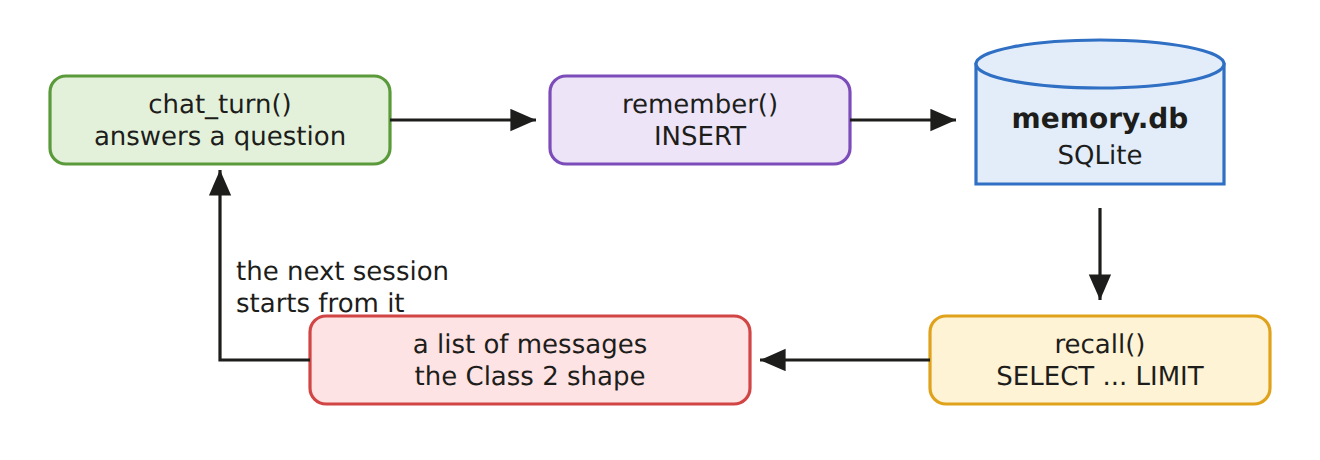

### Step 1 — The Class 4 functions, in short

In [ ]:
knowledge = {
    "class": "The course has 10 classes.",
    "teach": "Alexandra Oliveira and Catarina Santos teach this course.",
    "colab": "We write our code in Google Colab.",
}

def clean_text(text):
    """Return the text in lower case, without spaces at the ends."""
    return text.lower().strip()

def find_answer(question):
    """The stand-in model: answer from the knowledge dictionary."""
    for keyword in knowledge:
        if keyword in question:
            return knowledge[keyword]
    return "Sorry, I don't know that yet."

### Step 2 — `remember()`: save one turn

The `INSERT` from Section 4, wrapped in a function — so the rest of the program saves a turn in one line.

In [ ]:
def remember(user, question, answer, rating):
    """Save one conversation turn in the database."""
    cursor.execute(
        "INSERT INTO memory (user, question, answer, rating) VALUES (?, ?, ?, ?)",
        (user, question, answer, rating),
    )
    connection.commit()

### Step 3 — A chat turn that remembers

Here the user's rating is given with the question, so the whole conversation runs without typing.

In [ ]:
def chat_turn(user, question, rating):
    """Answer one question, and save the turn in long-term memory."""
    question = clean_text(question)
    answer = find_answer(question)
    remember(user, question, answer, rating)
    return answer

print(chat_turn("dora", "  Who TEACHES this course? ", 5))
print(chat_turn("dora", "Is Colab free?", 4))
print(chat_turn("dora", "what about the EXAM?", 1))

### Step 4 — `recall()`: reload a user's recent turns as messages

`ORDER BY id DESC LIMIT ?` gives the user's most recent turns, newest first. Each row becomes two messages: the user's question and the assistant's answer.

In [ ]:
def recall(user, n):
    """Return the user's n most recent turns, as a list of chat messages."""
    cursor.execute(
        "SELECT question, answer FROM memory WHERE user = ? ORDER BY id DESC LIMIT ?",
        (user, n),
    )
    history = []
    for question, answer in cursor.fetchall():
        history.append({"role": "user", "content": question})
        history.append({"role": "assistant", "content": answer})
    return history

In [ ]:
for message in recall("dora", 2):
    print(f"{message['role']}: {message['content']}")

### Step 5 — Learn from the feedback

Every answer was saved with its rating, so the answers users disliked are one query away — the list to review, and to add to FALC-ON AI's knowledge.

In [ ]:
cursor.execute("SELECT user, question, answer FROM memory WHERE rating < 3")

for user, question, answer in cursor.fetchall():
    print(f"{user}: {question} -> {answer}")

### Step 6 — Close the connection

In [ ]:
connection.close()
print("Saved and closed. Download memory.db from the files panel to keep it.")

---

### 🎉 That's Class 7!

| Concept | Key syntax |
|---------|------------|
| A tuple | `("ana", 5)`, `("ana",)`, `user, rating = row` |
| Open and close | `sqlite3.connect("memory.db")`, `connection.close()` |
| Run SQL | `cursor = connection.cursor()`, `cursor.execute("...")` |
| Save changes | `connection.commit()` |
| Create a table | `CREATE TABLE IF NOT EXISTS memory (col TYPE, ...)` |
| Add rows | `INSERT INTO memory (...) VALUES (?, ?)`, `.executemany()` |
| Read | `SELECT cols FROM memory WHERE ... ORDER BY ... LIMIT ...` |
| Collect | `.fetchall()`, `.fetchone()` |
| Change / remove | `UPDATE memory SET col = ? WHERE ...`, `DELETE FROM memory WHERE ...` |
| Count the rows | `len(cursor.fetchall())` |
| Database → pandas | `pd.read_sql_query(sql, connection)` |
| pandas → database | `df.to_sql("name", connection, if_exists="replace", index=False)` |

> ⚠️ **The three that will catch you:** forgetting `commit()`, so nothing is saved; forgetting the `WHERE` on an `UPDATE` or `DELETE`, so every row changes; re-running an `INSERT` cell, so your rows double.

> 🤖 **The big picture:** FALC-ON AI now has a long-term memory: every turn and every rating is stored, can be reloaded as a conversation, and can be queried to find what went wrong. Real assistants work the same way.

➡️ Now open the **exercises notebook**.